In [14]:
from ga4_churn_predictor.config import PROCESSED_DATA_DIR
from ga4_churn_predictor.config import DATA_PATH
import pandas
import seaborn
import matplotlib.pyplot as pyplot

dataframe = pandas.read_parquet(DATA_PATH)

dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 3409 entries, 0 to 3408
Data columns (total 27 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   id_usuario                            3409 non-null   str    
 1   dispositivo                           3409 non-null   str    
 2   meio_acesso                           3409 non-null   str    
 3   meio_trafego                          3409 non-null   str    
 4   fonte_trafego                         3409 non-null   str    
 5   total_pedidos                         3409 non-null   Int64  
 6   receita_total_em_usd                  3409 non-null   float64
 7   ticket_medio_em_usd                   3409 non-null   float64
 8   data_primeiro_pedido                  3409 non-null   dbdate 
 9   data_ultimo_pedido                    3409 non-null   dbdate 
 10  recencia_dias                         3409 non-null   Int64  
 11  dias_desde_primeiro_pedido  

In [15]:
dataframe = dataframe.drop_duplicates(subset=["id_usuario"], ignore_index=False)

mediana_total_interacoes = dataframe["total_interacoes"].median()
mediana_total_interacoes_page_view = dataframe["total_interacoes_page_view"].median()
mediana_total_interacoes_view_search_results = dataframe["total_interacoes_view_search_results"].median()
mediana_total_interacoes_view_item_list = dataframe["total_interacoes_view_item_list"].median()
mediana_total_interacoes_select_item = dataframe["total_interacoes_select_item"].median()
mediana_total_interacoes_select_promotion = dataframe["total_interacoes_select_promotion"].median()
mediana_total_interacoes_add_to_cart = dataframe["total_interacoes_add_to_cart"].median()
mediana_total_interacoes_begin_checkout = dataframe["total_interacoes_begin_checkout"].median()
mediana_total_interacoes_quinzena_1 = dataframe["total_interacoes_quinzena_1"].median()
mediana_total_interacoes_quinzena_2 = dataframe["total_interacoes_quinzena_2"].median()
mediana_total_interacoes_quinzena_3 = dataframe["total_interacoes_quinzena_3"].median()
mediana_total_interacoes_quinzena_4 = dataframe["total_interacoes_quinzena_4"].median()

dataframe["total_interacoes"] = dataframe["total_interacoes"].fillna(mediana_total_interacoes)
dataframe["total_interacoes_page_view"] = dataframe["total_interacoes_page_view"].fillna(mediana_total_interacoes_page_view)
dataframe["total_interacoes_view_search_results"] = dataframe["total_interacoes_view_search_results"].fillna(mediana_total_interacoes_view_search_results)
dataframe["total_interacoes_view_item_list"] = dataframe["total_interacoes_view_item_list"].fillna(mediana_total_interacoes_view_item_list)
dataframe["total_interacoes_select_item"] = dataframe["total_interacoes_select_item"].fillna(mediana_total_interacoes_select_item)
dataframe["total_interacoes_select_promotion"] = dataframe["total_interacoes_select_promotion"].fillna(mediana_total_interacoes_select_promotion)
dataframe["total_interacoes_add_to_cart"] = dataframe["total_interacoes_add_to_cart"].fillna(mediana_total_interacoes_add_to_cart)
dataframe["total_interacoes_begin_checkout"] = dataframe["total_interacoes_begin_checkout"].fillna(mediana_total_interacoes_begin_checkout)
dataframe["total_interacoes_quinzena_1"] = dataframe["total_interacoes_quinzena_1"].fillna(mediana_total_interacoes_quinzena_1)
dataframe["total_interacoes_quinzena_2"] = dataframe["total_interacoes_quinzena_2"].fillna(mediana_total_interacoes_quinzena_2)
dataframe["total_interacoes_quinzena_3"] = dataframe["total_interacoes_quinzena_3"].fillna(mediana_total_interacoes_quinzena_3)
dataframe["total_interacoes_quinzena_4"] = dataframe["total_interacoes_quinzena_4"].fillna(mediana_total_interacoes_quinzena_4)
dataframe["revendedor"] = dataframe["total_itens_comprados"].map(lambda x: 1 if x > 30 else 0)

dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 3409 entries, 0 to 3408
Data columns (total 28 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   id_usuario                            3409 non-null   str    
 1   dispositivo                           3409 non-null   str    
 2   meio_acesso                           3409 non-null   str    
 3   meio_trafego                          3409 non-null   str    
 4   fonte_trafego                         3409 non-null   str    
 5   total_pedidos                         3409 non-null   Int64  
 6   receita_total_em_usd                  3409 non-null   float64
 7   ticket_medio_em_usd                   3409 non-null   float64
 8   data_primeiro_pedido                  3409 non-null   dbdate 
 9   data_ultimo_pedido                    3409 non-null   dbdate 
 10  recencia_dias                         3409 non-null   Int64  
 11  dias_desde_primeiro_pedido  

In [16]:
dataframe.describe()

,total_pedidos,receita_total_em_usd,ticket_medio_em_usd,recencia_dias,dias_desde_primeiro_pedido,tempo_relacionamento_dias,total_itens_comprados,total_interacoes,total_interacoes_page_view,total_interacoes_view_search_results,...,total_interacoes_select_item,total_interacoes_select_promotion,total_interacoes_add_to_cart,total_interacoes_begin_checkout,total_interacoes_quinzena_1,total_interacoes_quinzena_2,total_interacoes_quinzena_3,total_interacoes_quinzena_4,churn,revendedor
count,3409.0,3409.000000,3409.000000,3409.0,3409.0,3409.0,3409.0,3409.0,3409.0,3409.0,...,3409.0,3409.0,3409.0,3409.0,3409.0,3409.0,3409.0,3409.0,3409.0,3409.000000
mean,1.316515,89.414784,69.096275,29.688765,30.619537,0.930771,5.648284,59.787914,51.234966,0.607216,...,2.076855,0.13787,5.720739,0.0,9.228806,15.969199,25.370783,9.12467,0.894984,0.021707
std,0.947179,116.366152,80.645136,14.426099,14.433671,4.582565,11.84437,47.461993,40.38762,2.296856,...,4.196601,0.445768,9.495121,0.0,22.849422,30.093281,41.285133,25.436402,0.306619,0.145747
min,1.0,0.000000,0.000000,1.0,1.0,0.0,0.0,6.0,6.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
25%,1.0,30.000000,26.000000,19.0,20.0,0.0,2.0,27.0,24.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.000000
50%,1.0,55.000000,48.000000,28.0,29.0,0.0,3.0,46.0,39.0,0.0,...,0.0,0.0,2.0,0.0,0.0,0.0,2.0,0.0,1.0,0.000000
75%,1.0,101.000000,84.000000,40.0,42.0,0.0,6.0,77.0,66.0,0.0,...,2.0,0.0,7.0,0.0,5.0,23.0,38.0,0.0,1.0,0.000000
max,16.0,1530.000000,1530.000000,61.0,61.0,53.0,400.0,500.0,424.0,75.0,...,54.0,8.0,98.0,0.0,500.0,269.0,373.0,363.0,1.0,1.000000


In [17]:
display(dataframe["dispositivo"].unique())
display(dataframe["meio_acesso"].unique())
display(dataframe["meio_trafego"].unique())
display(dataframe["fonte_trafego"].unique())

<ArrowStringArray>
['mobile', 'desktop', 'tablet']
Length: 3, dtype: str

<ArrowStringArray>
['WEB']
Length: 1, dtype: str

<ArrowStringArray>
['organic', 'referral', '(none)', '(data deleted)', '<Other>', 'cpc']
Length: 6, dtype: str

<ArrowStringArray>
[                         'google', 'shop.googlemerchandisestore.com',
                        '(direct)',                         '<Other>',
                  '(data deleted)']
Length: 5, dtype: str

Devido à enorme diferença entre a quantidade de clientes que deram churn e a quantidade de clientes que não deram churn, deverá ser utilizado o balanceamento de classes ao treinar o modelo.

<Axes: xlabel='churn', ylabel='count'>

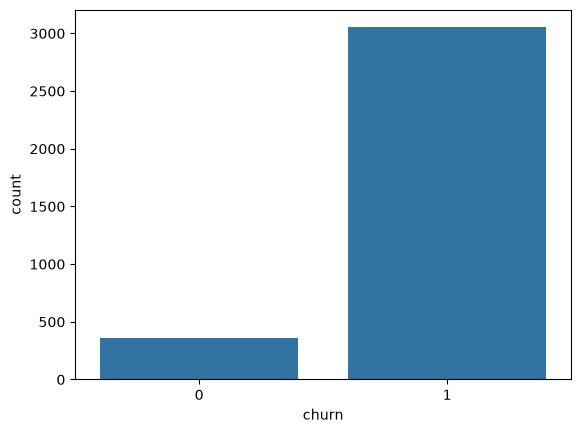

In [18]:
seaborn.countplot(
    data=dataframe,
    x="churn"
)

Colunas relevantes para predição do churn
- recencia_dias
- dias_desde_primeiro_pedido
- tempo_relacionamento_dias
- total_interacoes
- tendencia_interacoes

As colunas de total de interações por quinzena e a métrica gerada de tendência das interações dizem essencialmente a mesma coisa. Já que a tendência das interações segrega de forma ainda mais intensa os usuários que deram churn ou não do que qualquer outra coluna de total de interações, a estratégia ideal é descartar essas colunas e incluir apenas a tendência no treinamento do modelo.

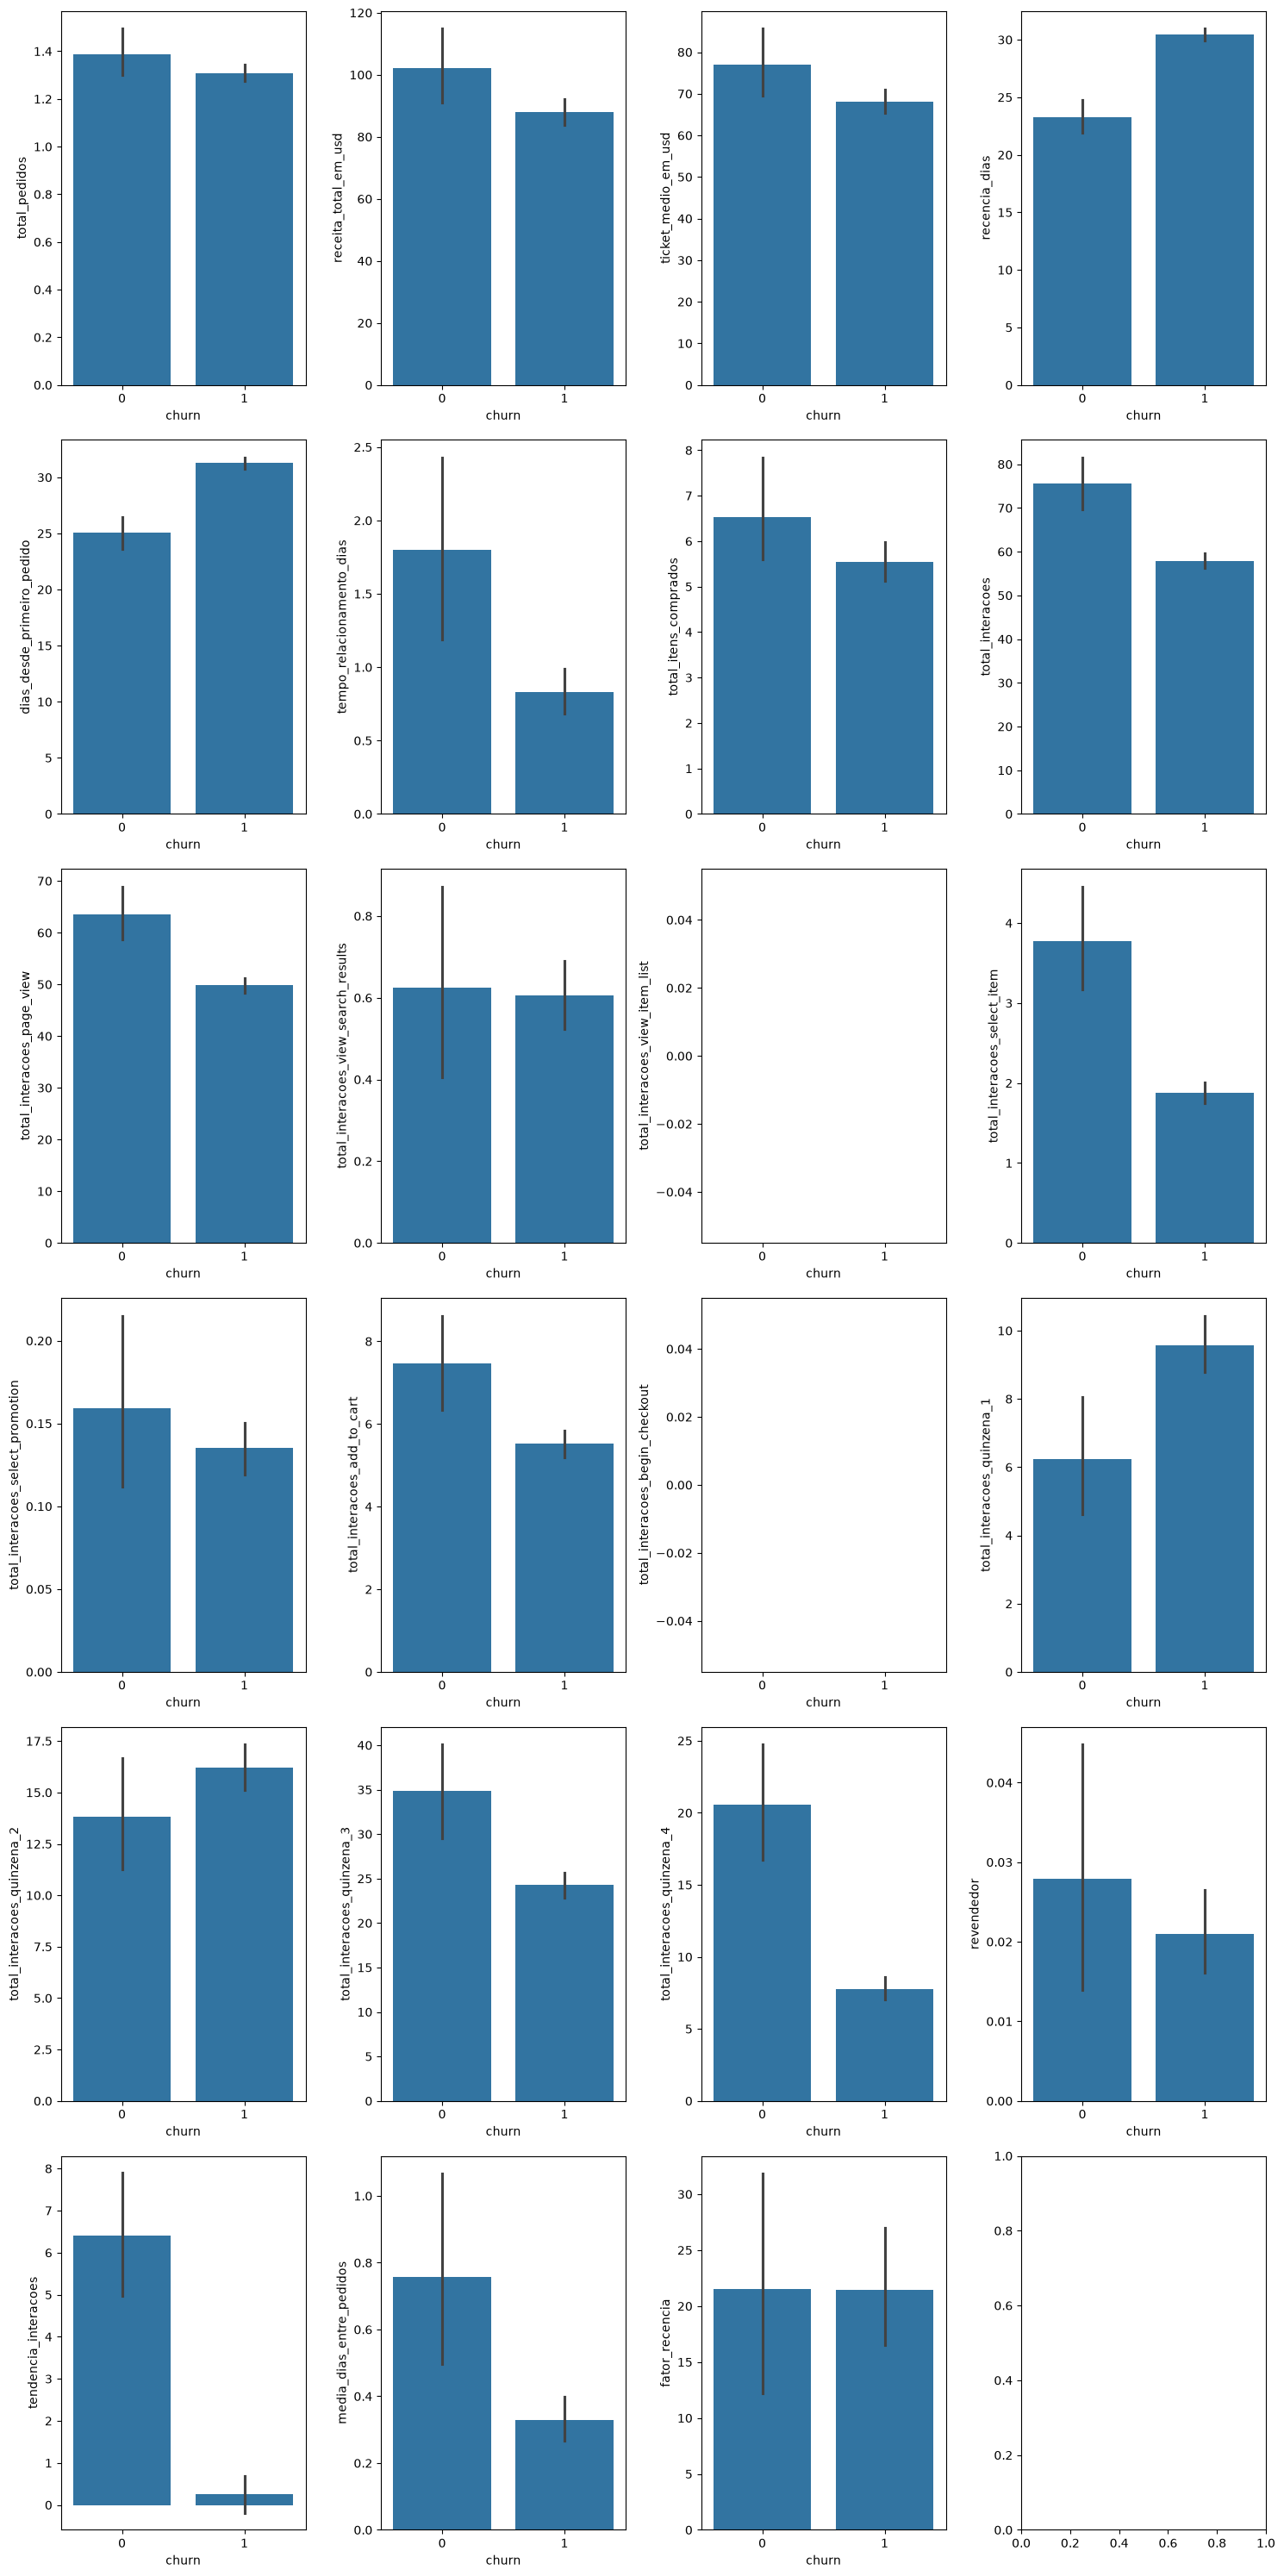

In [19]:
import math

dataframe["tendencia_interacoes"] = (-6 * dataframe["total_interacoes_quinzena_1"] - 2 * dataframe["total_interacoes_quinzena_2"] + 2 * dataframe["total_interacoes_quinzena_3"] + 6 * dataframe["total_interacoes_quinzena_4"])/20
dataframe["media_dias_entre_pedidos"] = dataframe["tempo_relacionamento_dias"] / dataframe["total_pedidos"]
dataframe["fator_recencia"] = dataframe["recencia_dias"] / dataframe["media_dias_entre_pedidos"]

numeric_columns = dataframe.select_dtypes(include="number").columns.drop("churn")

figure, axes = pyplot.subplots(6, 4, figsize=(15, 30))
flattened_axes = axes.flatten()

for index in range(0, len(numeric_columns)):
    seaborn.barplot(
        data=dataframe,
        x="churn",
        y=numeric_columns[index],
        ax=flattened_axes[index]
    )

pyplot.tight_layout()
pyplot.show()

<Axes: >

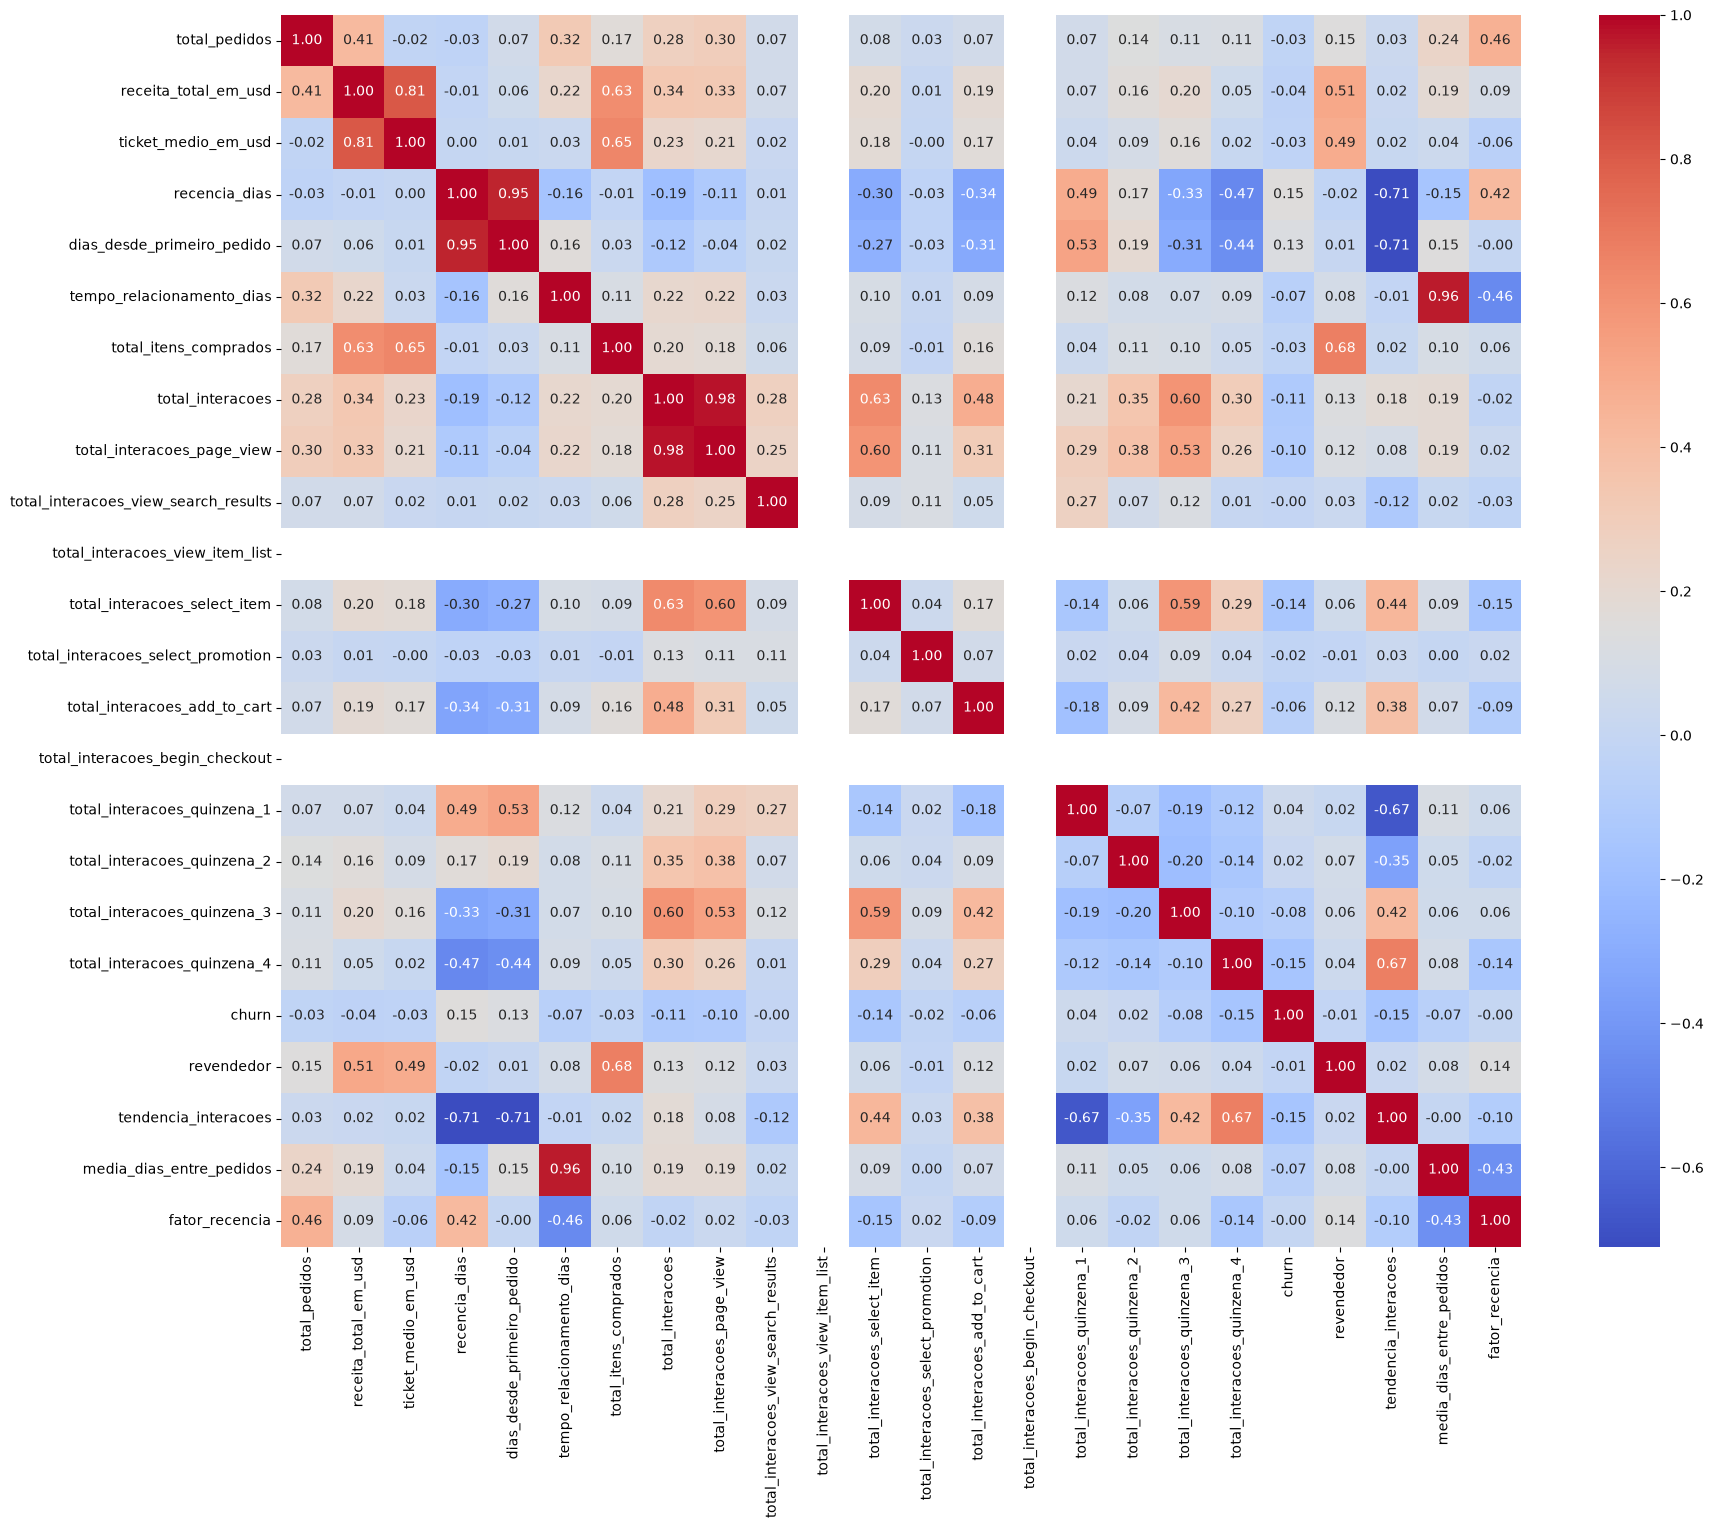

In [20]:
pyplot.figure(figsize=(20, 16))

seaborn.heatmap(data=dataframe.select_dtypes(include="number").corr(), annot=True, fmt=".2f", cmap="coolwarm")

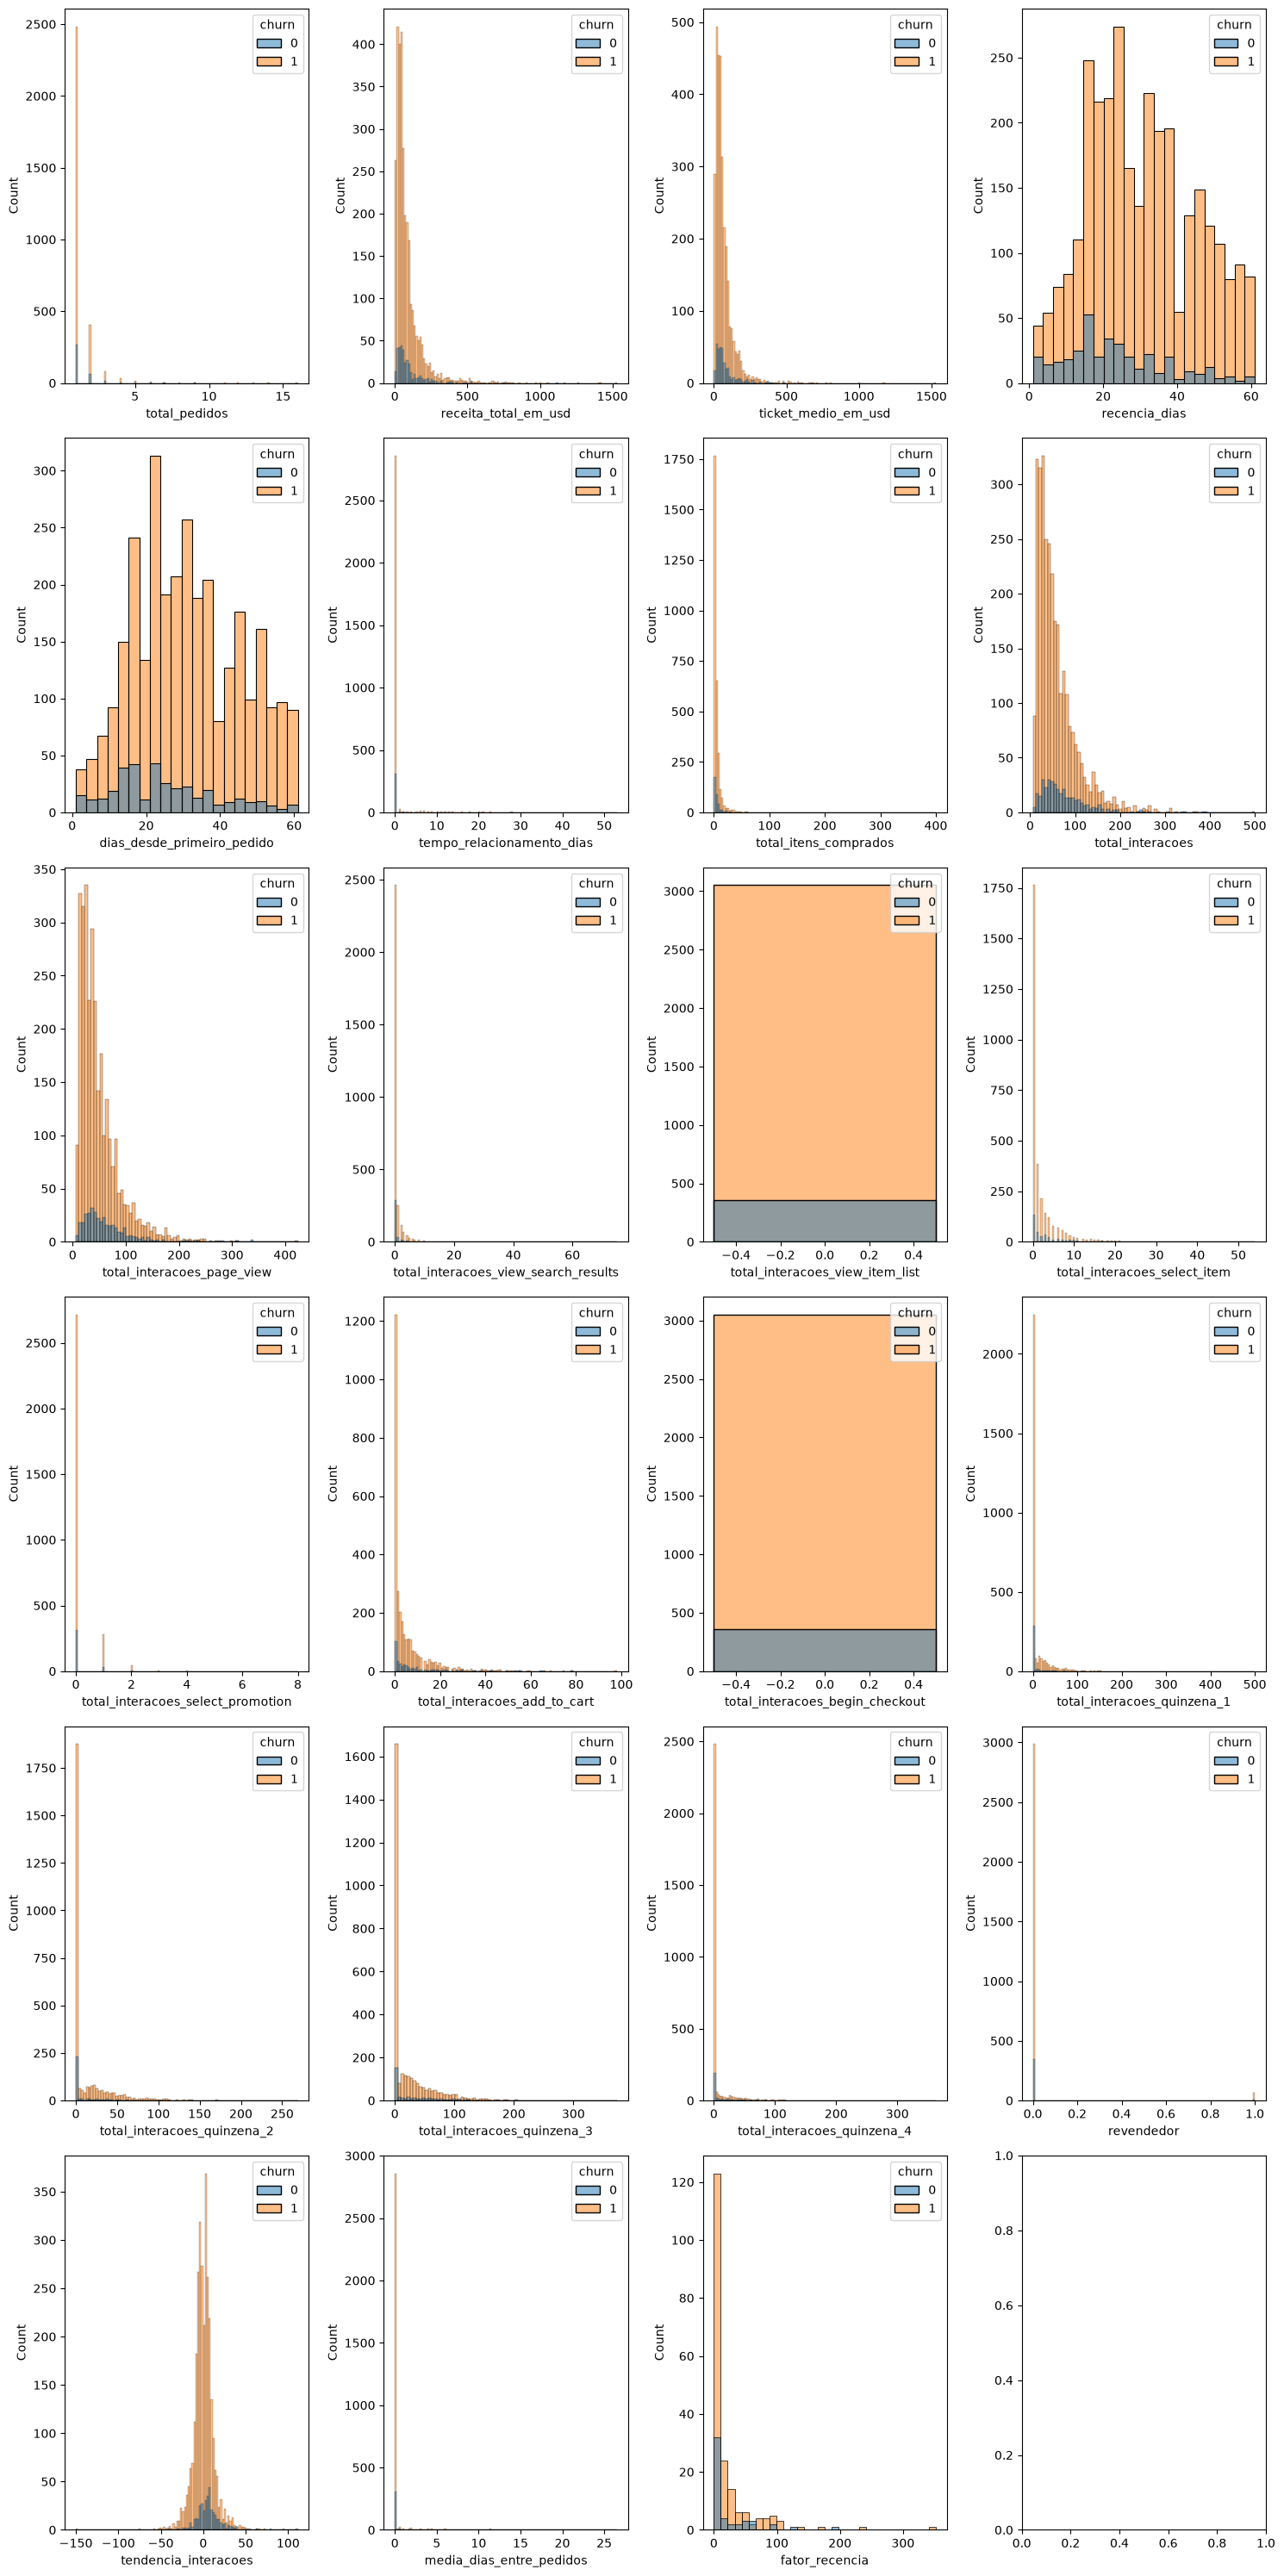

In [21]:
numeric_columns = dataframe.select_dtypes(include="number").columns.drop("churn")

figure, axes = pyplot.subplots(6, 4, figsize=(15, 30))
flattened_axes = axes.flatten()

for index in range(0, len(numeric_columns)):
    seaborn.histplot(
        data=dataframe,
        x=numeric_columns[index],
        hue="churn",
        ax=flattened_axes[index],
    )

pyplot.tight_layout()
pyplot.show()

<Axes: xlabel='total_itens_comprados', ylabel='Count'>

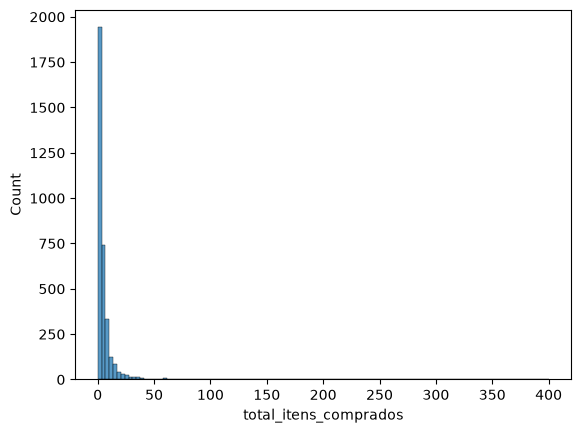

In [22]:
dataframe["media_dias_entre_pedidos"] = dataframe["tempo_relacionamento_dias"] / dataframe["total_pedidos"]

seaborn.histplot(
    data=dataframe,
    x="total_itens_comprados",
)

<Axes: ylabel='churn'>

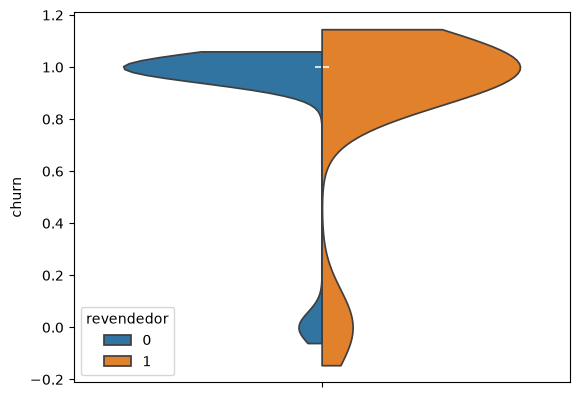

In [23]:
seaborn.violinplot(
    data=dataframe,
    y="churn",
    hue="revendedor",
    split=True,
    cut=True
)

<Axes: xlabel='revendedor', ylabel='media_dias_entre_pedidos'>

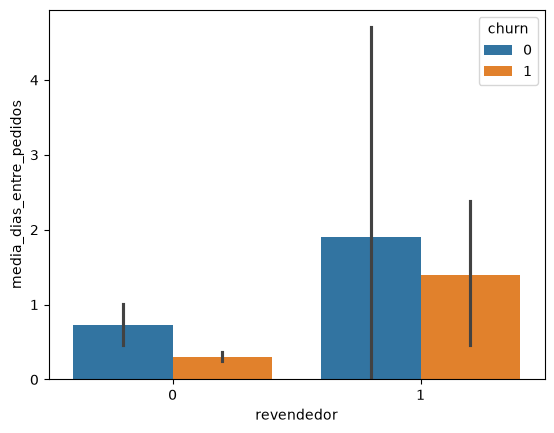

In [24]:
seaborn.barplot(
    data=dataframe,
    y="media_dias_entre_pedidos",
    x="revendedor",
    hue="churn"
)